In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta.

In [4]:
pregunta_1 = "1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  "
pregunta_2 = "2. C y D son consecutivas y tienen la misma holgura total. El responsable de C pide retrasarla 1 semanas y el de D también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  "
pregunta_3 = "3. Compruébelo: recalcule el calendario con C retrasada 1 semanas y después con las dos retrasadas.  "
pregunta_4 = "4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 1 semanas entre C y D?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

2. C y D son consecutivas y tienen la misma holgura total. El responsable de C pide retrasarla 1 semanas y el de D también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

3. Compruébelo: recalcule el calendario con C retrasada 1 semanas y después con las dos retrasadas.  

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 1 semanas entre C y D?  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 4       ),
    ('C'     , '---'      , 1       ),
    ('D'     , 'C'        , 7       ),
    ('E'     , 'A,B'      , 2       ),
    ('F'     , 'D,E'      , 3       ),
    ('G'     , 'D'        , 1       ),
    ('H'     , 'F,G'      , 8       ),
    ('I'     , 'H'        , 4       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,4
C,---,1
D,C,7
E,"A,B",2
F,"D,E",3
G,D,1
H,"F,G",8
I,H,4


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
duracion_proyecto = proyecto.duration(datos_proyecto['duration'])

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto con las holguras total, libre e independiente.  

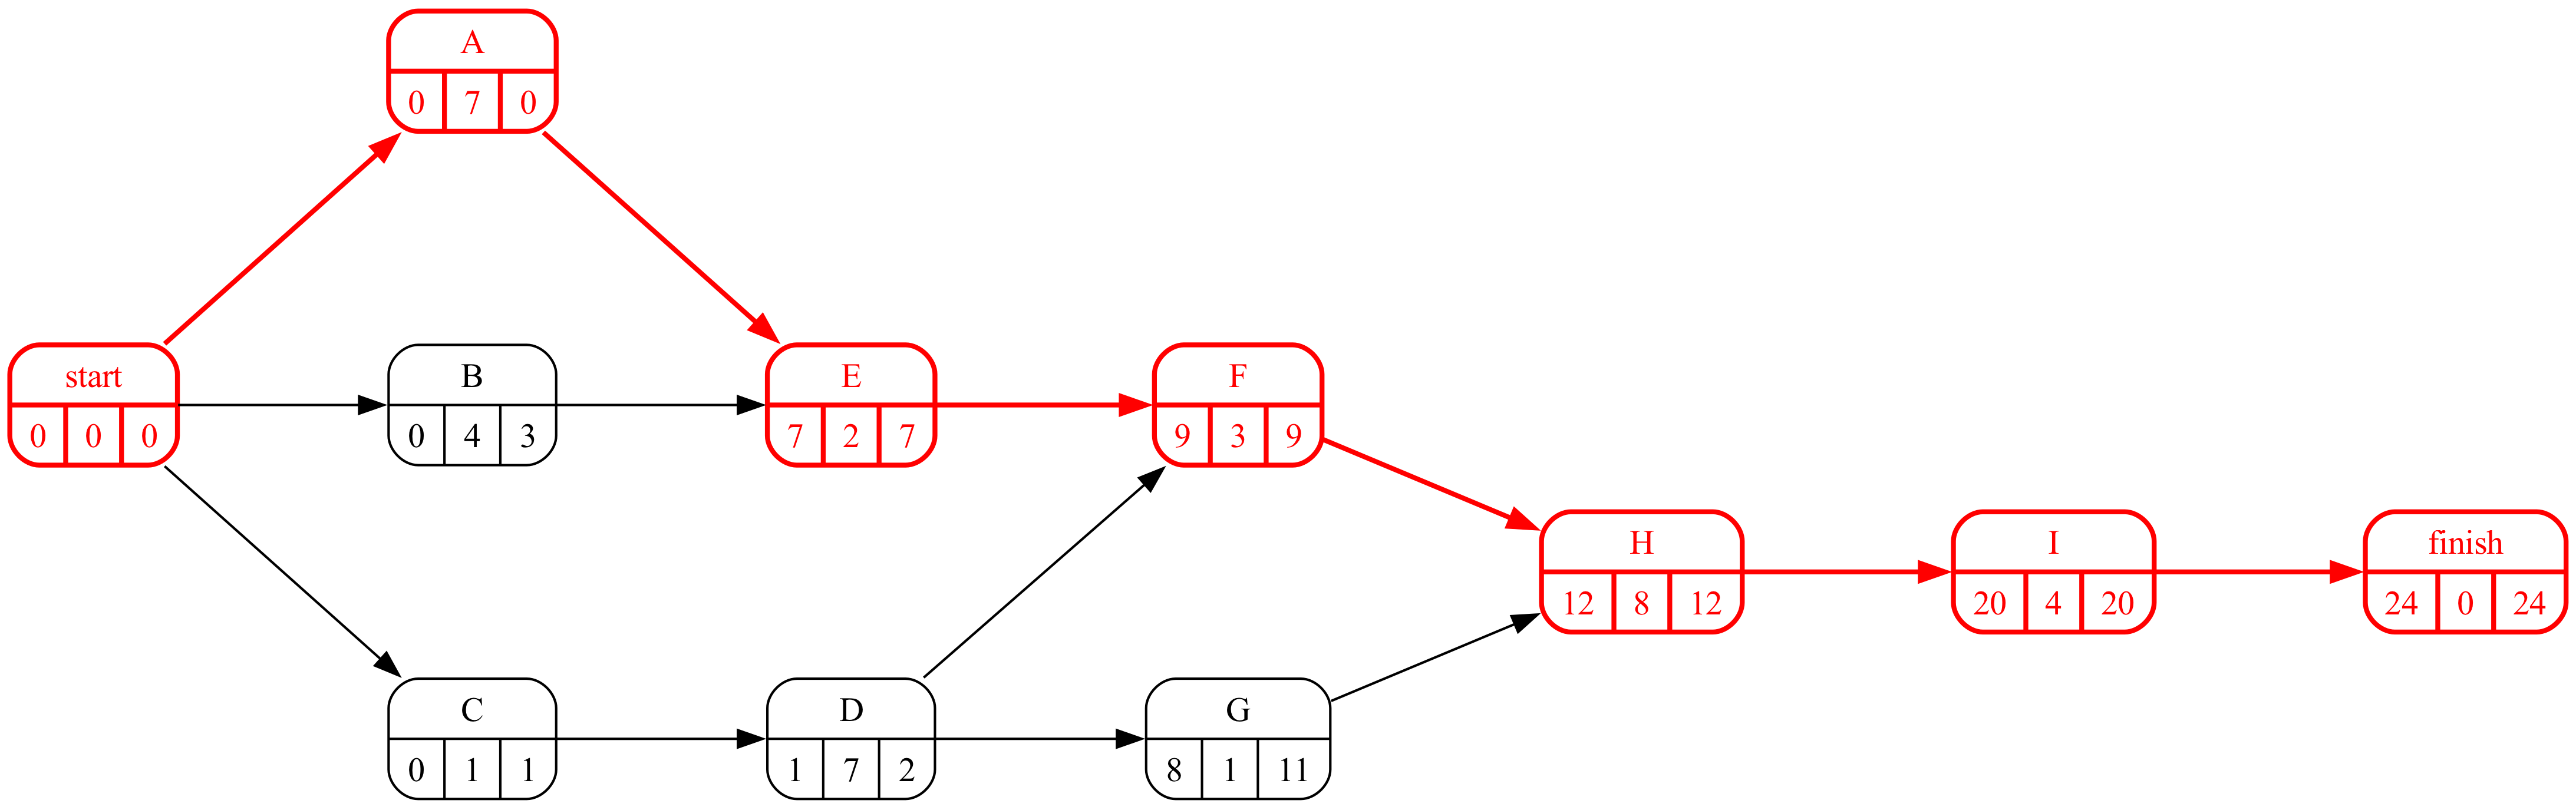

In [8]:
#| fig-cap: "Grafo Roy con tiempos y camino crítico"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

In [9]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,7,7,0,0,0,7
B,0,3,4,7,3,3,3,4
C,0,1,1,2,0,0,1,1
D,1,2,8,9,0,0,1,7
E,7,7,9,9,0,0,0,2
F,9,9,12,12,0,0,0,3
G,8,11,9,12,3,2,3,1
H,12,12,20,20,0,0,0,8
I,20,20,24,24,0,0,0,4


Con los números sustituidos, actividad a actividad (ES, EF, LS y LF son inicio y fin más tempranos y más tardíos; «pred.» y «suc.» las predecesoras y sucesoras inmediatas):

In [10]:
#| tbl-cap: "Cálculo paso a paso de fechas y holguras"
#| label: tbl-holgurasPaso
detalle_holguras(calendario, prelaciones)

,ES = máx EF pred.,EF = ES + d,LF = mín LS suc.,LS = LF − d,H_total = LS − ES,H_libre = mín ES suc. − EF,"H_indep. = máx(0, mín ES suc. − máx LF pred. − d)"
actividad,,,,,,,
A,inicial → 0,0 + 7 = 7,mín(E: 7) = 7,7 − 7 = 0,0 − 0 = 0,7 − 7 = 0,"máx(0, 7 − 0 − 7) = 0"
B,inicial → 0,0 + 4 = 4,mín(E: 7) = 7,7 − 4 = 3,3 − 0 = 3,7 − 4 = 3,"máx(0, 7 − 0 − 4) = 3"
C,inicial → 0,0 + 1 = 1,mín(D: 2) = 2,2 − 1 = 1,1 − 0 = 1,1 − 1 = 0,"máx(0, 1 − 0 − 1) = 0"
D,máx(C: 1) = 1,1 + 7 = 8,"mín(F: 9, G: 11) = 9",9 − 7 = 2,2 − 1 = 1,8 − 8 = 0,"máx(0, 8 − 2 − 7) = 0"
E,"máx(A: 7, B: 4) = 7",7 + 2 = 9,mín(F: 9) = 9,9 − 2 = 7,7 − 7 = 0,9 − 9 = 0,"máx(0, 9 − 7 − 2) = 0"
F,"máx(D: 8, E: 9) = 9",9 + 3 = 12,mín(H: 12) = 12,12 − 3 = 9,9 − 9 = 0,12 − 12 = 0,"máx(0, 12 − 9 − 3) = 0"
G,máx(D: 8) = 8,8 + 1 = 9,mín(H: 12) = 12,12 − 1 = 11,11 − 8 = 3,12 − 9 = 3,"máx(0, 12 − 9 − 1) = 2"
H,"máx(F: 12, G: 9) = 12",12 + 8 = 20,mín(I: 20) = 20,20 − 8 = 12,12 − 12 = 0,20 − 20 = 0,"máx(0, 20 − 12 − 8) = 0"
I,máx(H: 20) = 20,20 + 4 = 24,final → 24,24 − 4 = 20,20 − 20 = 0,24 (fin) − 24 = 0,"máx(0, 24 − 20 − 4) = 0"


## Apartado 2

In [11]:
display(Markdown(pregunta_2))

2. C y D son consecutivas y tienen la misma holgura total. El responsable de C pide retrasarla 1 semanas y el de D también. ¿Pueden concederse las dos peticiones sin alargar el proyecto? Razónelo antes de calcular.  

No. La holgura total de C y la de D son la *misma* holgura: la de la cadena en la que están. C tiene holgura libre cero, así que cualquier retraso suyo mueve el inicio de D y le consume holgura. Si C gasta las 1 semanas, D se queda sin ninguna; si además D se retrasa, el proyecto se alarga.

## Apartado 3

In [12]:
display(Markdown(pregunta_3))

3. Compruébelo: recalcule el calendario con C retrasada 1 semanas y después con las dos retrasadas.  

In [13]:
X, Y, h = 'C', 'D', 1
d1 = datos_proyecto['duration'].copy(); d1[X] += h
d2 = d1.copy(); d2[Y] += h
cal1, cal2 = proyecto.calendar(d1), proyecto.calendar(d2)
pd.DataFrame({'original': calendario.loc[[X, Y], 'H_total'], f'{X} retrasada {h}': cal1.loc[[X, Y], 'H_total'],
              'las dos retrasadas': cal2.loc[[X, Y], 'H_total']})

,original,C retrasada 1,las dos retrasadas
activity,,,
C,1,0,0
D,1,0,0


In [14]:
Markdown(f'Duración del proyecto: {duracion_proyecto} semanas en la planificación original, {proyecto.duration(d1)} con {X} retrasada '
         f'y **{proyecto.duration(d2)}** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.')

Duración del proyecto: 24 semanas en la planificación original, 24 con C retrasada y **25** con las dos retrasadas: el segundo retraso ya no cabe en la holgura.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué holgura expresa cuánto puede retrasarse cada una sin quitarle margen a la otra? ¿Cómo repartiría las 1 semanas entre C y D?  

In [16]:
Markdown(f'''La holgura libre de {X} es {int(calendario.loc[X, "H_libre"])}: es lo que puede retrasarse sin mover a {Y}. La holgura independiente de {Y} es {int(calendario.loc[Y, "H_independiente"])}: lo que puede retrasarse {Y} aunque {X} acabe lo más tarde posible. Las {h} semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ {h} entre {X} y {Y} respeta el plazo; lo que no es posible es que cada una disponga de {h} por su cuenta.''')

La holgura libre de C es 0: es lo que puede retrasarse sin mover a D. La holgura independiente de D es 0: lo que puede retrasarse D aunque C acabe lo más tarde posible. Las 1 semanas son un recurso compartido de la cadena: cualquier reparto x + y ≤ 1 entre C y D respeta el plazo; lo que no es posible es que cada una disponga de 1 por su cuenta.